# Experiment 2 - Error Statistics (multi-seed)

Fits the mixed-selective model to the Bays (2014) reference at several population
seeds, so every reported number is a mean with a 95% confidence interval across
independent population draws (Correction 3). Figures follow the axis rules of
Correction 7. Set size is written $l$ in figures; in the code it is `N`.

## Setup


In [41]:
# Setup for the Notebook

import sys
from pathlib import Path
PROJECT_ROOT = str(Path.cwd().parents[1])
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import os
import time
import datetime
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.ticker import ScalarFormatter, NullLocator, FixedLocator
from matplotlib.colors import Normalize
from scipy.special import logsumexp, i0, i1
from scipy.optimize import brentq, least_squares
from scipy.stats import vonmises

# GP framework
from core.encoder.gaussian_process import generate_neuron_population
from core.encoder.divisive_normalization import dn_pointwise
from core.encoder.poisson_spike import generate_spikes
from core.decoder.ml_decoder import decode

# All circular metrics -- including the per-trial decoder error -- come
# from the central metrics module (single source of truth). Only
# run_multiloc_trials (the trial engine) stays in core.population.
from core.population import run_multiloc_trials
from core.metrics import (
    circular_error,
    circular_variance_fisher,
    circular_kurtosis_fisher,
    circular_moments,
    vonmises_kde,
    _direct_circular_variance,
    _kde_circular_variance,
)

# Bays cache loader — single source of truth for the comparison reference
from core.bays_cache import load_bays_cache, list_available_caches

In [42]:
from pathlib import Path
root = Path.cwd().parents[1]
hits = list(root.rglob("bays_cache*.py"))
print("bays_cache module(s):", [str(p.relative_to(root)) for p in hits])
# also check for an __init__.py that makes 'simulated_experiments' a package
print("simulated_experiments/__init__.py exists:",
      (root / "simulated_experiments" / "__init__.py").exists())

bays_cache module(s): []
simulated_experiments/__init__.py exists: True


In [43]:
# === Notebook configuration ===
# Bays generating params come FROM the cache meta (no separate shared-constants
# file). We load the fixed M=100 reference using the loader's canonical
# defaults, then read the parameters off its metadata.

M_BAYS_REF = 100
bays_errors, bays_meta = load_bays_cache(M=M_BAYS_REF)   # loader defaults -> canonical cache

OMEGA_BAYS       = bays_meta['omega']
GAMMA_TOTAL_BAYS = bays_meta['gamma_total']
T_D              = bays_meta['T_d']
SEED             = bays_meta['seed']
SET_SIZES        = list(bays_meta['set_sizes'])
LAMBDA_BASE      = np.sqrt(OMEGA_BAYS)      # M-independent

# --- Genuine notebook-side config (NOT stored in the cache) ---
N_THETA        = 128
SIGMA_SQ       = 1e-6
N_BINS         = 50
KAPPA_BAYS_AC  = 80.0     # von Mises KDE smoothing for the Bays reference curves

print('=== Notebook config (Bays params read from cache meta) ===')
print(f'  reference cache = {bays_meta["cache_filename"]}  (fixed M={M_BAYS_REF})')
print(f'  omega={OMEGA_BAYS}  gamma_total={GAMMA_TOTAL_BAYS} Hz  T_d={T_D}s  seed={SEED}')
print(f'  set sizes = {SET_SIZES}')


=== Notebook config (Bays params read from cache meta) ===
  reference cache = bays_cache_omega0.52_gamma119_M100_N10000_seed12345.npz  (fixed M=100)
  omega=0.52  gamma_total=119.0 Hz  T_d=0.1s  seed=12345
  set sizes = [1, 2, 3, 4, 5, 6, 7, 8]


## Experiment Control

Single source of truth for the whole notebook.

- **`M`** - population size. Fits to the Bays reference use **M = 100**, the size
  of the reference population. Bays's error distribution depends only on total
  gain, but the mixed-selective model's errors also depend on population size, so
  the two models are compared at the same size.
- **`DISTRIBUTION`** - how tuning *width* is sampled across locations:
  `'folded_normal'`, `'gamma'`, or `'sparse_sharp'`.
- **`MODEL`** - the generative tuning model: `'gp'`, `'vm'` or `'bays'`, all built
  by `generate_neuron_population` in `core.encoder.gaussian_process`.
- **`N_SEEDS`** - number of independent population draws. Each replicate draws a
  new population and new trials and is fitted on its own. Start with the 5-seed
  pilot; the pilot analysis at the end of the notebook recommends the final number.

In [44]:
# === EXPERIMENT CONTROL (the only M / DISTRIBUTION / MODEL / seed knob) ===
M            = 100      # fits to the Bays reference use the reference's own size
DISTRIBUTION = 'sparse_sharp'  # 'folded_normal' | 'gamma' | 'sparse_sharp'
MODEL        = 'gp'     # 'gp' | 'vm' | 'bays'

# sparse_sharp knobs (ignored unless DISTRIBUTION == 'sparse_sharp')
N_HIGH          = 1
HIGH_MULTIPLIER = 3.0

# Amplitude variability (kept 0 to match the homogeneous Bays model)
GAIN_VARIABILITY = 0.0

# --- Population seeds (Correction 3) ------------------------------------------
# Replicate s draws a NEW population and NEW trials and is fitted on its own.
# Replicate 0 uses seed base SEED, so it reproduces the single-seed results.
# The stride keeps every seed role disjoint: fit trials (+l), plotted predictions
# (+7000+l), held-out cost (+50000+l) and the moment pool (+90000+l).
N_SEEDS     = 10          # pilot size; set to the pilot's recommendation for the final run
SEED_STRIDE = 100_000
SEED_BASES  = [SEED + SEED_STRIDE * s for s in range(N_SEEDS)]

assert DISTRIBUTION in ('folded_normal', 'gamma', 'sparse_sharp'), DISTRIBUTION
assert MODEL in ('gp', 'vm', 'bays'), MODEL
assert N_SEEDS >= 1, N_SEEDS

# Each sampler's heterogeneity parameter (the value the sweep varies):
#   gamma         -> coefficient of variation (CV) of the widths
#   folded_normal -> sigma_lambda, the spread of the width factor
#   sparse_sharp  -> jitter around the base width; most of its heterogeneity
#                    comes from the one sharp location (base width / HIGH_MULTIPLIER)
HET_TEXT, HET_TEX, HET_KEY = {
    'gamma':         ('CV', 'CV', 'cv'),
    'folded_normal': ('sigma_lambda', r'$\sigma_\lambda$', 'sigma_lambda'),
    'sparse_sharp':  ('jitter', 'jitter', 'jitter'),
}[DISTRIBUTION]

# --- ONE shared output directory for this run ---
#   result_data / experiment_2 / <date> / <distribution>_<size>_<model>_<n>seeds / <timestamp>
EXPERIMENT_TAG = 'experiment_2'
_date = datetime.datetime.now().strftime('%Y%m%d')
_time = datetime.datetime.now().strftime('%H%M%S')
# Results live next to this notebook: simulated_experiments/bays_2014/result_data.
# (The folder used to be called 'experiments'; writing there silently created a stray tree.)
EXPERIMENTS_DIR = Path(PROJECT_ROOT) / 'simulated_experiments' / 'bays_2014'
assert EXPERIMENTS_DIR.is_dir(), f'Expected the bays_2014 folder at {EXPERIMENTS_DIR}'
RESULT_BASE = EXPERIMENTS_DIR / 'result_data'
OUTPUT_DIR  = (RESULT_BASE / EXPERIMENT_TAG / _date /
               f'{DISTRIBUTION}_{M}_{MODEL}_{N_SEEDS}seeds' / _time)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('=== Experiment control (global) ===')
print(f'  M            = {M}')
print(f'  DISTRIBUTION = {DISTRIBUTION!r}')
print(f'  MODEL        = {MODEL!r}')
if DISTRIBUTION == 'sparse_sharp':
    print(f'  N_HIGH={N_HIGH}  HIGH_MULTIPLIER={HIGH_MULTIPLIER}')
print(f'  heterogeneity parameter = {HET_TEXT}')
print(f'  N_SEEDS      = {N_SEEDS}  (seed bases {SEED_BASES})')
print(f'  gamma per neuron (Bays-equivalent) = GAMMA_TOTAL_BAYS / M = {GAMMA_TOTAL_BAYS / M:.4f} Hz')
print(f'  Bays reference = fixed M={M_BAYS_REF}')
print(f'  OUTPUT_DIR   = {OUTPUT_DIR}')

=== Experiment control (global) ===
  M            = 100
  DISTRIBUTION = 'sparse_sharp'
  MODEL        = 'gp'
  N_HIGH=1  HIGH_MULTIPLIER=3.0
  heterogeneity parameter = jitter
  N_SEEDS      = 10  (seed bases [12345, 112345, 212345, 312345, 412345, 512345, 612345, 712345, 812345, 912345])
  gamma per neuron (Bays-equivalent) = GAMMA_TOTAL_BAYS / M = 1.1900 Hz
  Bays reference = fixed M=100
  OUTPUT_DIR   = /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_2/20261020/sparse_sharp_100_gp_10seeds/143436


## Model Framework

Tuning-curve generation lives in `core.encoder.gaussian_process`
(`generate_neuron_population`, which now dispatches on `model` for GP / VM /
Bays), and the vectorised continuous-theta trial engine lives in
`core.population` (`run_multiloc_trials`, imported above). The notebook only
assembles arguments and orchestrates the fit - it does not reimplement
generation or the trial loop.

The single dispatcher below turns the fit's free *width* parameter into a
population under the chosen `MODEL` and returns `(thetas, f_all)` ready for
`run_multiloc_trials`.


In [45]:
# === Population dispatcher: one place that assembles generation args ===
# `width` is the fit's free width parameter, interpreted per MODEL:
#   MODEL='gp'            -> width is the GP base lengthscale (lambda)
#   MODEL in ('vm','bays') -> width is the Von Mises width (omega)
# f_all is a list over locations, each (M, n_theta), for run_multiloc_trials.
def build_population(width, sigma, seed):
    max_locs = max(SET_SIZES)
    kw = dict(
        n_neurons=M, n_orientations=N_THETA, n_locations=max_locs,
        base_lengthscale=width, lengthscale_variability=sigma,
        seed=seed, gain_variability=GAIN_VARIABILITY, model=MODEL,
    )
    if MODEL in ('gp', 'vm'):
        kw['method'] = DISTRIBUTION
        if DISTRIBUTION == 'sparse_sharp':
            kw.update(n_high=N_HIGH, high_multiplier=HIGH_MULTIPLIER)
    if MODEL in ('vm', 'bays'):
        kw['omega'] = width          # width is omega for VM / Bays
    population = generate_neuron_population(**kw)
    thetas = population[0]['orientations']
    f_all = [np.array([population[n]['f_samples'][loc, :] for n in range(M)])
             for loc in range(max_locs)]
    return thetas, f_all


## Model to Bays Parameters Fit - one fit per population seed

Fits (`width`, `gamma`, `sigma`) separately at every seed in `SEED_BASES`, with the
grid + Nelder-Mead search defined below, to the fixed M = 100 Bays reference.

Reporting: means with t-based 95% confidence intervals across seeds (n - 1 degrees
of freedom). Circular variance is positive and spans orders of magnitude, so it is
averaged on the log scale (geometric mean, CI back-transformed). Each fit's cost is
also re-evaluated on **held-out trials** the fit never saw, as a check against
fitting the particular trial noise.

In [46]:
# === Model to Bays Parameters Fit - bind to the global control ===
# Uses the single global M / DISTRIBUTION (control cell in Setup). Fits the GP
# (M neurons) to the FIXED M=100 Bays reference loaded in the config cell.
FIT_OUTPUT_DIR = OUTPUT_DIR
fit_bays_errors, fit_bays_meta = bays_errors, bays_meta   # the fixed M=100 reference

print('=== Model to Bays Parameters Fit ===')
print(f'  M              = {M}')
print(f'  MODEL          = {MODEL!r}')
print(f'  DISTRIBUTION   = {DISTRIBUTION!r}')
if DISTRIBUTION == 'sparse_sharp':
    print(f'  N_HIGH={N_HIGH}  HIGH_MULTIPLIER={HIGH_MULTIPLIER}')
print(f'  Bays reference = {fit_bays_meta["cache_filename"]}  (fixed M={M_BAYS_REF})')


=== Model to Bays Parameters Fit ===
  M              = 100
  MODEL          = 'gp'
  DISTRIBUTION   = 'sparse_sharp'
  N_HIGH=1  HIGH_MULTIPLIER=3.0
  Bays reference = bays_cache_omega0.52_gamma119_M100_N10000_seed12345.npz  (fixed M=100)


In [47]:
# === Fit configuration: optimizer setup driven by the global Experiment Control ===

# --- Restrict THIS notebook to the classic Bays set sizes -------------------
# The reference cache carries all of 1..8; figure 2 uses only 1, 2, 4, 8. Pin
# SET_SIZES so the fit target, the fit, and the overlay all use the same four.
SET_SIZES = [1, 2, 4, 8]

N_DATA       = 10000   # MUST equal the cache's trial count
N_TRIALS_FIT = 1000    # forward trials per evaluation. Every evaluation reuses
                       # the same seeds (common random numbers), so the cost is
                       # deterministic and directly comparable between parameter
                       # sets. More trials = lower noise floor, slower fits.
SEED_FIT     = SEED

# --- Fit objective -----------------------------------------------------------
#   'histogram' : residual over the 50-bin error histograms (default; full shape)
#   'moments'   : residual over (circular variance, kurtosis) per set size
FIT_OBJECTIVE = 'histogram'

# Histogram grid for the residual
N_BINS_FIT  = 50
BIN_EDGES   = np.linspace(-np.pi, np.pi, N_BINS_FIT + 1)
BIN_CENTERS = 0.5 * (BIN_EDGES[:-1] + BIN_EDGES[1:])

# --- Bounds -------------------------------------------------------------------
# The gain bounds are set on the TOTAL population gain and converted to
# per-neuron values, so they mean the same thing at every M. (They used to be
# per-neuron, [0.1, 10] Hz: 10-1000 Hz total at M=100 but 100-10000 Hz total at
# M=1000, which pinned the M=1000 fits against the 100 Hz floor.)
GAMMA_TOTAL_LO, GAMMA_TOTAL_HI = 5.0, 2000.0      # Hz, whole population
WIDTH_LO, WIDTH_HI             = 0.1, 3.0
if DISTRIBUTION == 'folded_normal':
    SIGMA_LO, SIGMA_HI = 0.0, 2.0
    SIGMA_TARGET = 0.0     # Bays is homogeneous; expect sigma -> 0
    SIGMA_NAME   = 'sigma_lambda'
else:  # 'gamma' or 'sparse_sharp'  (gamma needs CV > 0)
    SIGMA_LO, SIGMA_HI = 0.01, 10.0
    SIGMA_TARGET = 0.01    # near the lower bound; Bays is homogeneous
    SIGMA_NAME   = 'cv'
LO = [WIDTH_LO, GAMMA_TOTAL_LO / M, SIGMA_LO]
HI = [WIDTH_HI, GAMMA_TOTAL_HI / M, SIGMA_HI]

# Recovery targets (model-dependent width mapping: GP fits lambda = sqrt(omega);
# VM / Bays fit omega directly).
LAMBDA_TARGET = np.sqrt(OMEGA_BAYS) if MODEL == 'gp' else OMEGA_BAYS
GAMMA_TARGET  = GAMMA_TOTAL_BAYS / M

# --- Search strategy: coarse grid, then Nelder-Mead ---------------------------
# The simulated cost is piecewise constant in the parameters: decoded
# orientations sit on an n_theta grid and spike counts are integers, so a small
# parameter change usually leaves every simulated error unchanged and then
# jumps. Gradient-based least_squares therefore shrank its trust region to
# ~1e-9 and stopped on `xtol` close to wherever it started. A coarse grid finds
# the right region; a derivative-free Nelder-Mead search (in log-parameters)
# then refines it.
GRID_LAMBDA      = np.geomspace(0.35, 2.0, 6)             # GP lengthscale values
GRID_WIDTH       = GRID_LAMBDA if MODEL == 'gp' else GRID_LAMBDA ** 2
GRID_GAMMA_TOTAL = np.geomspace(20.0, 640.0, 6)            # Hz, whole population
GRID_SIGMA       = max(0.1, SIGMA_LO)                       # heterogeneity during the grid stage
NM_MAXFEV        = 80      # Nelder-Mead evaluation budget (main 3-parameter fit)
NM_STEP          = 0.15    # initial simplex step in log units (about 16%)

# The physics reduction point is added to the grid as one extra candidate.
X0 = [LAMBDA_TARGET, GAMMA_TARGET, max(0.05, SIGMA_LO)]
DIFF_STEP = 0.05   # kept only for the fit log's schema; the grid + Nelder-Mead search does not use it

print(f'Optimizer configuration  (M={M}, model={MODEL}, distribution={DISTRIBUTION}):')
print(f'  objective   = {FIT_OBJECTIVE!r}')
print(f'  search      = {len(GRID_WIDTH)}x{len(GRID_GAMMA_TOTAL)} grid at {SIGMA_NAME}={GRID_SIGMA}, '
      f'then Nelder-Mead (<= {NM_MAXFEV} evaluations)')
print(f'  bounds      = width [{WIDTH_LO}, {WIDTH_HI}], gamma_total [{GAMMA_TOTAL_LO}, {GAMMA_TOTAL_HI}] Hz, '
      f'{SIGMA_NAME} [{SIGMA_LO}, {SIGMA_HI}]')
print(f'  trials/eval = {N_TRIALS_FIT}')
print(f'  set sizes (figure 2) = {SET_SIZES}')
print(f'  Bays-equivalent point: lambda={LAMBDA_TARGET:.4f}, '
      f'gamma={GAMMA_TARGET:.4f} per neuron ({GAMMA_TOTAL_BAYS:.0f} Hz total)')

# Build fit targets from the cached Bays errors (subset to the four fig-2 sizes).
data_errors  = {N: fit_bays_errors[N] for N in SET_SIZES}
data_hists   = {}
data_moments = {}
for N in SET_SIZES:
    h, _ = np.histogram(data_errors[N], bins=BIN_EDGES, density=True)
    data_hists[N]   = h
    data_moments[N] = circular_moments(data_errors[N])
data_vector = np.concatenate([data_hists[N] for N in SET_SIZES])
print(f'  Data vector shape (histogram): {data_vector.shape}')


Optimizer configuration  (M=100, model=gp, distribution=sparse_sharp):
  objective   = 'histogram'
  search      = 6x6 grid at cv=0.1, then Nelder-Mead (<= 80 evaluations)
  bounds      = width [0.1, 3.0], gamma_total [5.0, 2000.0] Hz, cv [0.01, 10.0]
  trials/eval = 1000
  set sizes (figure 2) = [1, 2, 4, 8]
  Bays-equivalent point: lambda=0.7211, gamma=1.1900 per neuron (119 Hz total)
  Data vector shape (histogram): (200,)


In [48]:
# === Robust fitter: coarse grid search, then Nelder-Mead refinement ===
# Shared by the Bays self-check, the main fit, and the fixed-CV sweep.
from types import SimpleNamespace
from scipy.optimize import minimize


def sse_cost(residual_vector):
    """0.5 * sum of squared residuals: the same scale as least_squares' `cost`,
    so costs remain comparable with earlier fit logs."""
    r = np.asarray(residual_vector, dtype=float)
    return 0.5 * float(r @ r)


def bounded_cache_put(cache, key, value, max_items=8):
    """Insert into a dict used as a small FIFO cache (populations are ~8 MB each)."""
    cache[key] = value
    while len(cache) > max_items:
        cache.pop(next(iter(cache)))


def fit_grid_nm(cost_fn, candidates, lo, hi, nm_maxfev=80, nm_step=0.15,
                label='fit', verbose=True):
    """Minimise a deterministic cost by grid search, then Nelder-Mead.

    cost_fn    : callable(np.ndarray) -> float. Must use fixed seeds, so the
                 same parameters always give the same cost.
    candidates : parameter vectors (natural units) evaluated first.
    lo, hi     : bounds in natural units; every evaluation is clipped inside.
    Nelder-Mead works in log-parameters, so steps are relative and all
    parameters stay positive. The result is never worse than the best grid
    point. Returns a namespace with x, cost, nfev, status, success, message,
    grid_x, grid_cost, at_grid_edge and optimality (nan: no gradient is used).
    """
    lo = np.asarray(lo, dtype=float)
    hi = np.asarray(hi, dtype=float)
    floor_lo = np.maximum(lo, 1e-3)          # log-space needs a positive floor
    log_lo, log_hi = np.log(floor_lo), np.log(hi)
    memo = {}

    def evaluate(x):
        x = np.clip(np.asarray(x, dtype=float), floor_lo, hi)
        key = tuple(np.round(np.log(x), 6))
        if key not in memo:
            memo[key] = float(cost_fn(x))
        return memo[key]

    t_start = time.time()
    grid_x = [np.clip(np.asarray(c, dtype=float), floor_lo, hi) for c in candidates]
    grid_cost = np.array([evaluate(x) for x in grid_x])
    i_best = int(np.argmin(grid_cost))
    x_grid_best = grid_x[i_best]

    # Warn when the best grid point lies on the grid's edge in a varied dimension.
    gx = np.array(grid_x)
    at_edge = []
    for j in range(gx.shape[1]):
        vals = np.unique(np.round(gx[:, j], 9))
        if vals.size > 2 and (np.isclose(x_grid_best[j], vals[0]) or np.isclose(x_grid_best[j], vals[-1])):
            at_edge.append(j)
    if verbose:
        print(f'  [{label}] grid: {len(grid_x)} points, best cost {grid_cost[i_best]:.4f} '
              f'at {np.round(x_grid_best, 4)}  ({time.time() - t_start:.0f}s)')
        if at_edge:
            print(f'  [{label}] WARNING: best grid point is on the grid edge for parameter(s) '
                  f'{at_edge}; consider widening the grid.')

    z0 = np.log(x_grid_best)
    d = z0.size
    simplex = np.vstack([z0] + [z0 + nm_step * np.eye(d)[j] for j in range(d)])
    nm = minimize(lambda z: evaluate(np.exp(np.clip(z, log_lo, log_hi))), z0,
                  method='Nelder-Mead',
                  options=dict(initial_simplex=simplex, xatol=0.01, fatol=1e-4,
                               maxfev=nm_maxfev, adaptive=True))
    x_best = np.exp(np.clip(nm.x, log_lo, log_hi))
    cost_best = evaluate(x_best)
    if grid_cost[i_best] < cost_best:
        x_best, cost_best = x_grid_best, float(grid_cost[i_best])

    if verbose:
        print(f'  [{label}] Nelder-Mead: cost {cost_best:.4f} at {np.round(x_best, 4)} '
              f'({len(memo)} evaluations, {time.time() - t_start:.0f}s total; {nm.message})')

    return SimpleNamespace(
        x=x_best, cost=float(cost_best), optimality=float('nan'),
        nfev=len(memo), status=int(nm.status), success=bool(nm.success),
        message=str(nm.message), grid_x=gx, grid_cost=grid_cost,
        at_grid_edge=bool(at_edge),
    )

print('fit_grid_nm ready.')


fit_grid_nm ready.


### Sanity check: Bays self-fit

Before fitting the GP model, check the reference data and the fitting procedure on a problem whose answer is known.

* **Part A** regenerates the cached Bays errors from the simulator that built them, once with the cache's own seeds (should be identical) and once with fresh seeds (should overlap closely). This confirms the `.npz` file is what its metadata claims.
* **Part B** fits the Bays simulator itself to the cache with the same grid + Nelder-Mead search used below. It should reach the **noise floor**, the cost of the true parameters, which is the best cost any model can achieve at `N_TRIALS_FIT` trials. Use it as the benchmark for the GP fits. Width and gain trade off against each other along a ridge, so the recovered parameters are only expected to land within about 25% of the truth.


Part A: regenerate the cache
   N  identical  overlap  var cache  var fresh  kurt cache  kurt fresh
   1    100.00%    0.986     0.0734     0.0745       1.394       2.187
   2    100.00%    0.971     0.1770     0.1860       3.709       4.115
   4    100.00%    0.978     0.4577     0.4492       3.178       3.064
   8    100.00%    0.968     1.0153     1.0393       1.286       1.282
  identical: share of trials reproduced exactly from the cache seeds (expect ~100%).
  overlap  : histogram overlap with a fresh-seed replicate (1 = identical; expect ~0.97 or higher at 10,000 trials).

Part B: fit the Bays simulator to the cache
  [Bays self-fit] grid: 36 points, best cost 0.1140 at [  0.6428 149.4877]  (2s)
  [Bays self-fit] Nelder-Mead: cost 0.0723 at [  0.6192 141.3163] (93 evaluations, 6s total; Optimization terminated successfully.)
  noise floor (true parameters, 1000 trials/eval) = 0.1130
  self-fit cost = 0.0723  -> PASS: reaches the noise floor
  omega       : 0.619  (true 0.52, +19

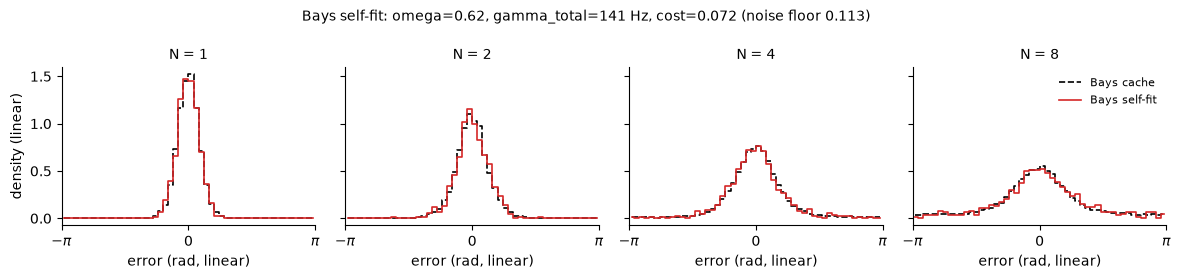

In [49]:
# === Sanity check: Bays self-fit (cache integrity + optimizer recovery) ===
from core.bays_cache.build_bays_cache import bays_run_trials_vectorised

RUN_BAYS_SELF_CHECK = True
BAYS_M        = int(bays_meta.get('M', M_BAYS_REF))
BAYS_DECODE   = int(bays_meta.get('n_decode_grid', 1000))
SELF_SEED     = SEED + 424242            # fresh seeds, never used by the cache
BIN_WIDTH     = BIN_EDGES[1] - BIN_EDGES[0]


def bays_forward(omega, gamma_total, N, n_trials, seed):
    return bays_run_trials_vectorised(
        n_trials=n_trials, set_size=N, omega=omega, gamma_total=gamma_total,
        T_d=T_D, M=BAYS_M, rng=np.random.RandomState(seed), n_decode_grid=BAYS_DECODE)


def bays_forward_hist(omega, gamma_total, n_trials, seed_base):
    return np.concatenate([
        np.histogram(bays_forward(omega, gamma_total, N, n_trials, seed_base + N),
                     bins=BIN_EDGES, density=True)[0]
        for N in SET_SIZES])


if RUN_BAYS_SELF_CHECK:
    # ---- Part A: is the cache what it claims to be? ----------------------------
    print('Part A: regenerate the cache')
    print(f'  {"N":>2}  {"identical":>9}  {"overlap":>7}  {"var cache":>9}  {"var fresh":>9}  '
          f'{"kurt cache":>10}  {"kurt fresh":>10}')
    for N in SET_SIZES:
        n = len(data_errors[N])
        regen = bays_forward(OMEGA_BAYS, GAMMA_TOTAL_BAYS, N, n, SEED + BAYS_M * 100 + N)
        identical = float(np.mean(np.isclose(regen, data_errors[N], atol=1e-9)))
        fresh = bays_forward(OMEGA_BAYS, GAMMA_TOTAL_BAYS, N, n, SELF_SEED + N)
        h_cache, _ = np.histogram(data_errors[N], bins=BIN_EDGES, density=True)
        h_fresh, _ = np.histogram(fresh, bins=BIN_EDGES, density=True)
        overlap = float(np.sum(np.minimum(h_cache, h_fresh)) * BIN_WIDTH)   # 1 = identical shape
        mc, mf = circular_moments(data_errors[N]), circular_moments(fresh)
        print(f'  {N:>2}  {identical:>9.2%}  {overlap:>7.3f}  {mc["variance"]:>9.4f}  '
              f'{mf["variance"]:>9.4f}  {mc["kurtosis"]:>10.3f}  {mf["kurtosis"]:>10.3f}')
    print('  identical: share of trials reproduced exactly from the cache seeds (expect ~100%).')
    print('  overlap  : histogram overlap with a fresh-seed replicate (1 = identical; '
          'expect ~0.97 or higher at 10,000 trials).')

    # ---- Part B: can the fitting procedure recover known parameters? -----------
    print('\nPart B: fit the Bays simulator to the cache')
    def bays_self_cost(p):
        return sse_cost(data_vector - bays_forward_hist(p[0], p[1], N_TRIALS_FIT, SELF_SEED + 1000))

    noise_floor = bays_self_cost(np.array([OMEGA_BAYS, GAMMA_TOTAL_BAYS]))
    self_candidates = [np.array([w, g])
                       for w in np.geomspace(0.2, 1.4, 6)
                       for g in np.geomspace(40.0, 360.0, 6)]
    self_fit = fit_grid_nm(bays_self_cost, self_candidates,
                           lo=[0.05, GAMMA_TOTAL_LO], hi=[4.0, GAMMA_TOTAL_HI],
                           nm_maxfev=60, nm_step=NM_STEP, label='Bays self-fit')
    omega_self, gamma_total_self = self_fit.x
    reaches_floor = self_fit.cost <= 1.25 * noise_floor
    print(f'  noise floor (true parameters, {N_TRIALS_FIT} trials/eval) = {noise_floor:.4f}')
    print(f'  self-fit cost = {self_fit.cost:.4f}  -> '
          f'{"PASS: reaches the noise floor" if reaches_floor else "FAIL: stops above the noise floor"}')
    print(f'  omega       : {omega_self:.3f}  (true {OMEGA_BAYS}, {100 * (omega_self / OMEGA_BAYS - 1):+.0f}%)')
    print(f'  gamma_total : {gamma_total_self:.1f} Hz  (true {GAMMA_TOTAL_BAYS}, '
          f'{100 * (gamma_total_self / GAMMA_TOTAL_BAYS - 1):+.0f}%)')
    print('  Width and gain trade off along a ridge, so parameter errors up to ~25% are expected;')
    print('  the cost test is the one that matters.')
    print(f'\n  Benchmark for the GP fits below: a cost near {noise_floor:.3f} is as good as '
          f'the data allow at {N_TRIALS_FIT} trials/eval.')

    # ---- Figure: cache vs self-fit (linear axes) ------------------------------
    self_hist = bays_forward_hist(omega_self, gamma_total_self, N_TRIALS_FIT,
                                  SELF_SEED + 1000).reshape(len(SET_SIZES), -1)
    fig, axes = plt.subplots(1, len(SET_SIZES), figsize=(12, 2.8), sharey=True)
    for ax, N, h_fit in zip(axes, SET_SIZES, self_hist):
        ax.step(BIN_CENTERS, data_hists[N], where='mid', color='k', ls='--', lw=1.2, label='Bays cache')
        ax.step(BIN_CENTERS, h_fit, where='mid', color='tab:red', lw=1.2, label='Bays self-fit')
        ax.set_title(f'N = {N}', fontsize=10)
        ax.set_xlim(-np.pi, np.pi)
        ax.set_xticks([-np.pi, 0, np.pi])
        ax.set_xticklabels([r'$-\pi$', '0', r'$\pi$'])
        ax.set_xlabel('error (rad, linear)')
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('density (linear)')
    axes[-1].legend(frameon=False, fontsize=8)
    fig.suptitle(f'Bays self-fit: omega={omega_self:.2f}, gamma_total={gamma_total_self:.0f} Hz, '
                 f'cost={self_fit.cost:.3f} (noise floor {noise_floor:.3f})', fontsize=10)
    fig.tight_layout()
    _self_png = FIT_OUTPUT_DIR / 'bays_self_fit.png'
    fig.savefig(_self_png, dpi=200, bbox_inches='tight')
    print(f'  saved {_self_png}')
    plt.show()


## Helpers: seed statistics, axis rules, figures

Axis rules applied to every figure in this notebook (Correction 7):

1. every axis carries at least two labelled ticks, on every panel;
2. log axes say "(log scale)" in their label, so any axis without it is linear;
3. variance uses a log y-axis; kurtosis uses a log y-axis only if every plotted
   value (including confidence bounds) is positive, otherwise a linear one;
4. set size is written $l$ (in the thesis, $N$ is the number of neurons).

Each figure cell prints the axis scales and the meaning of the error bars, ready
for the caption.

In [50]:
# === Helpers: statistics across seeds, axis rules and the fit figure ===
import matplotlib as mpl
from scipy import stats
from scipy.optimize import brentq
from matplotlib.colors import to_hex
from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter, MaxNLocator

CONF = 0.95

# ------------------------------------------------------------------ statistics
def mean_ci(values, conf=CONF):
    """Mean over axis 0 with a t-based CI. Returns (mean, lo, hi)."""
    x = np.asarray(values, dtype=float)
    m = np.nanmean(x, axis=0)
    n = x.shape[0]
    if n < 2:
        return m, m, m
    half = stats.t.ppf(0.5 + conf / 2, n - 1) * np.nanstd(x, axis=0, ddof=1) / np.sqrt(n)
    return m, m - half, m + half


def geo_mean_ci(values, conf=CONF):
    """Geometric mean and CI for positive quantities (CI on the log scale)."""
    m, lo, hi = mean_ci(np.log(np.asarray(values, dtype=float)), conf)
    return np.exp(m), np.exp(lo), np.exp(hi)


def ci_halfwidth_in_sd(n, conf=CONF):
    """95% CI half-width, in units of the between-seed SD, for n seeds."""
    return stats.t.ppf(0.5 + conf / 2, n - 1) / np.sqrt(n)


def paired_power(d, n, alpha=0.05):
    """Power of a two-sided paired t-test with standardised effect d and n seeds."""
    df = n - 1
    t_crit = stats.t.ppf(1 - alpha / 2, df)
    nc = abs(d) * np.sqrt(n)
    if nc > 37.0:                  # power is 1 here; scipy's noncentral t is unstable
        return 1.0
    power = stats.nct.sf(t_crit, df, nc) + stats.nct.cdf(-t_crit, df, nc)
    return float(power) if np.isfinite(power) else 1.0


def smallest_detectable_d(n, power=0.80, alpha=0.05):
    """Smallest standardised paired difference detected with the given power."""
    return brentq(lambda d: paired_power(d, n, alpha) - power, 1e-3, 20.0)


def seeds_for_power(d, power=0.80, alpha=0.05, n_max=200):
    """Seeds a paired t-test needs to detect effect d with the given power."""
    if not np.isfinite(d):
        return 2
    if d == 0:
        return np.inf
    for n in range(2, n_max + 1):
        if paired_power(d, n, alpha) >= power:
            return n
    return np.inf


def seeds_for_precision(sd, target_halfwidth, n_max=200, conf=CONF):
    """Seeds needed for the 95% CI half-width to fall to target_halfwidth."""
    if sd == 0:
        return 2
    for n in range(2, n_max + 1):
        if stats.t.ppf(0.5 + conf / 2, n - 1) * sd / np.sqrt(n) <= target_halfwidth:
            return n
    return np.inf


def sd_upper_limit(sd, n, level=0.80):
    """One-sided upper confidence limit of an SD estimated from n pilot seeds.

    A pilot SD from a handful of seeds is itself uncertain; planning with its
    upper limit guards against under-estimating the spread.
    """
    return sd * np.sqrt((n - 1) / stats.chi2.ppf(1 - level, n - 1))


def holm(pvalues):
    """Holm-Bonferroni adjusted p-values (NaN entries stay NaN)."""
    p = np.asarray(pvalues, dtype=float)
    adjusted = np.full_like(p, np.nan)
    ok = np.where(np.isfinite(p))[0]
    order = ok[np.argsort(p[ok])]
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(ok) - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


def summarise_seeds(seed_results):
    """Per-seed moments (rows: seeds, columns: set sizes) and their summaries."""
    var = np.array([[r['metric_moments'][N]['variance'] for N in SET_SIZES]
                    for r in seed_results])
    kurt = np.array([[r['metric_moments'][N]['kurtosis'] for N in SET_SIZES]
                     for r in seed_results])
    return {'var': var, 'kurt': kurt,
            'var_ci': geo_mean_ci(var), 'kurt_ci': mean_ci(kurt)}


# ------------------------------------------------------------------ figure style
NATURE_STYLE = {
    'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans', 'Helvetica', 'Arial'],
    'font.size': 8, 'axes.labelsize': 8, 'axes.titlesize': 9,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'axes.linewidth': 0.75, 'xtick.major.width': 0.75, 'ytick.major.width': 0.75,
    'xtick.major.size': 3.0, 'ytick.major.size': 3.0,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.2, 'savefig.dpi': 300, 'figure.dpi': 120,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
}
GP_COLOR, BAYS_COLOR, BAYS_LINESTYLE = '#D62728', '#000000', (0, (4, 2))
THETA_SMOOTH = np.linspace(-np.pi, np.pi, 500)

# Thesis copies are saved here under the file names the LaTeX already uses,
# ready to upload to Overleaf (images/results/ and appendix_figures/).
THESIS_FIG_DIR = Path(PROJECT_ROOT) / 'simulated_experiments' / 'thesis_figures' / 'experiment_2'


def thesis_name(base):
    """Thesis file name: plain for gamma (the thesis sampler), suffixed otherwise."""
    return base if DISTRIBUTION == 'gamma' else f'{base}_{DISTRIBUTION}'


def save_figure(fig, stem, thesis_stem=None):
    """Save PNG and PDF to OUTPUT_DIR, plus a thesis copy if thesis_stem is given.
    Confirms every file exists and returns the absolute paths."""
    targets = [(Path(OUTPUT_DIR), stem)]
    if thesis_stem is not None:
        targets.append((THESIS_FIG_DIR, thesis_stem))
    paths = []
    for folder, name in targets:
        folder = folder.resolve()
        folder.mkdir(parents=True, exist_ok=True)
        for ext in ('png', 'pdf'):
            path = folder / f'{name}.{ext}'
            fig.savefig(path, dpi=300, bbox_inches='tight')
            paths.append(path)
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise IOError(f'Figure not written: {missing}')
    return paths


def _style_axes(ax):
    for side in ('left', 'bottom'):
        ax.spines[side].set_linewidth(0.75)
    ax.tick_params(width=0.75, length=3.0, direction='out')


def _tick_label(value, _pos=None):
    return f'{value:g}'


def setsize_axis(ax):
    """Set size l on a log x-axis, ticks at the sampled set sizes only.
    The caption states that this axis is logarithmic."""
    ax.set_xscale('log')
    ax.set_xticks(SET_SIZES)
    ax.set_xticklabels([str(N) for N in SET_SIZES])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(SET_SIZES[0] / 1.25, SET_SIZES[-1] * 1.25)
    ax.set_xlabel(r'$l$')


def log_ylim(values, pad=1.6):
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v) & (v > 0)]
    if v.size == 0:
        return 0.01, 10.0
    return v.min() / pad, v.max() * pad


def log_y_axis(ax, lo, hi, label):
    """Log y-axis with at least two labelled ticks inside [lo, hi]."""
    ax.set_yscale('log')
    ax.set_ylim(lo, hi)
    k0, k1 = int(np.floor(np.log10(lo))), int(np.ceil(np.log10(hi)))
    ticks = [10.0 ** k for k in range(k0, k1 + 1) if lo <= 10.0 ** k <= hi]
    if len(ticks) < 2:                       # under two decades: 1-2-5 ticks
        ticks = [m * 10.0 ** k for k in range(k0 - 1, k1 + 1) for m in (1, 2, 5)
                 if lo <= m * 10.0 ** k <= hi]
    if len(ticks) < 2:                       # very narrow range: label the ends
        ticks = [lo, hi]
    while len(ticks) > 6:
        ticks = ticks[::2]
    ax.yaxis.set_major_locator(FixedLocator(ticks))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_formatter(FuncFormatter(_tick_label))
    ax.set_ylabel(label)


def linear_y_axis(ax, lo, hi, label):
    ax.set_yscale('linear')
    ax.set_ylim(lo, hi)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=2))
    ax.yaxis.set_minor_locator(NullLocator())
    ax.set_ylabel(label)


def kurtosis_axis_spec(values):
    """('log', lo, hi) if every value is positive, otherwise ('linear', lo, hi)."""
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    if v.size == 0:
        return ('linear', -1.0, 1.0)
    if v.min() > 0:
        lo, hi = log_ylim(v)
        return ('log', lo, hi)
    span = max(v.max() - v.min(), 1e-6)
    return ('linear', v.min() - 0.1 * span, v.max() + 0.1 * span)


def apply_kurtosis_axis(ax, spec):
    scale, lo, hi = spec
    if scale == 'log':
        log_y_axis(ax, lo, hi, r'$k$')
    else:
        linear_y_axis(ax, lo, hi, r'$k$')


def _panel_letter(ax, letter, x=-0.22, y=1.12):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=10, fontweight='bold', va='top')


def plot_fit_figure(seed_results, stem, thesis_stem=None, var_lim=None, kurt_spec=None):
    """Model (mean over seeds with 95% CI) against the Bays reference.

    a: error densities per set size (band = 95% CI across seeds);
    b: circular variance (geometric mean, 95% CI);
    c: circular kurtosis (mean, 95% CI).
    Returns the kurtosis-axis spec, so the caption can state its scale.
    """
    n_seeds = len(seed_results)
    summary = summarise_seeds(seed_results)
    var_bays = np.array([data_moments[N]['variance'] for N in SET_SIZES])
    kurt_bays = np.array([data_moments[N]['kurtosis'] for N in SET_SIZES])

    with mpl.rc_context(NATURE_STYLE):
        fig = plt.figure(figsize=(7.2, 4.6))
        gs = gridspec.GridSpec(2, len(SET_SIZES), height_ratios=[1.0, 0.8],
                               hspace=0.62, wspace=0.42,
                               left=0.08, right=0.98, bottom=0.10, top=0.88)

        kde_bays = {N: vonmises_kde(data_errors[N], THETA_SMOOTH, kappa=KAPPA_BAYS_AC)
                    for N in SET_SIZES}
        kde_model = {N: np.array([vonmises_kde(r['fitted_errors'][N], THETA_SMOOTH,
                                               kappa=KAPPA_BAYS_AC)
                                  for r in seed_results])
                     for N in SET_SIZES}
        ymax = 1.08 * max(max(k.max() for k in kde_bays.values()),
                          max(np.nanmax(mean_ci(k)[2]) for k in kde_model.values()))

        # ---- a: error densities (linear axes, every panel labelled) ----
        for i, N in enumerate(SET_SIZES):
            ax = fig.add_subplot(gs[0, i])
            m, lo, hi = mean_ci(kde_model[N])
            ax.fill_between(THETA_SMOOTH, np.maximum(lo, 0.0), hi,
                            color=GP_COLOR, alpha=0.20, lw=0)
            ax.plot(THETA_SMOOTH, kde_bays[N], color=BAYS_COLOR, lw=1.1,
                    linestyle=BAYS_LINESTYLE, label='Bays')
            ax.plot(THETA_SMOOTH, m, color=GP_COLOR, lw=1.1, label='Model')
            ax.set_xlim(-np.pi, np.pi)
            ax.set_xticks([-np.pi, 0, np.pi])
            ax.set_xticklabels([r'$-\pi$', '0', r'$\pi$'])
            ax.set_ylim(0, ymax)
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4, min_n_ticks=2))
            ax.xaxis.set_minor_locator(NullLocator())
            ax.yaxis.set_minor_locator(NullLocator())
            ax.set_title(f'$l = {N}$', fontsize=9, pad=4)
            ax.set_xlabel(r'$\varepsilon$ (rad)')
            if i == 0:
                ax.set_ylabel(r'$p(\varepsilon)$')
                _panel_letter(ax, 'a', x=-0.42, y=1.28)
            _style_axes(ax)
        handles, labels = fig.axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.0),
                   ncol=2, frameon=False, handlelength=2.2)

        # ---- b: circular variance (log y) ----
        gm, glo, ghi = summary['var_ci']
        ax_v = fig.add_subplot(gs[1, :2])
        ax_v.plot(SET_SIZES, var_bays, marker='o', color=BAYS_COLOR, lw=1.1, ms=3.5,
                  mfc='white', mew=0.9, linestyle=BAYS_LINESTYLE)
        ax_v.errorbar(SET_SIZES, gm, yerr=np.vstack([gm - glo, ghi - gm]),
                      marker='o', color=GP_COLOR, lw=1.1, ms=3.5, mfc='white',
                      mew=0.9, elinewidth=0.8, capsize=1.5)
        setsize_axis(ax_v)
        v_lo, v_hi = (var_lim if var_lim is not None
                      else log_ylim(np.concatenate([var_bays, glo, ghi])))
        log_y_axis(ax_v, v_lo, v_hi, r'$\sigma^2$')
        _panel_letter(ax_v, 'b', x=-0.16, y=1.15)
        _style_axes(ax_v)

        # ---- c: circular kurtosis (log y only if everything is positive) ----
        km, klo, khi = summary['kurt_ci']
        spec = (kurt_spec if kurt_spec is not None
                else kurtosis_axis_spec(np.concatenate([kurt_bays, klo, khi])))
        ax_k = fig.add_subplot(gs[1, 2:])
        ax_k.plot(SET_SIZES, kurt_bays, marker='o', color=BAYS_COLOR, lw=1.1, ms=3.5,
                  mfc='white', mew=0.9, linestyle=BAYS_LINESTYLE)
        ax_k.errorbar(SET_SIZES, km, yerr=np.vstack([km - klo, khi - km]),
                      marker='o', color=GP_COLOR, lw=1.1, ms=3.5, mfc='white',
                      mew=0.9, elinewidth=0.8, capsize=1.5)
        setsize_axis(ax_k)
        apply_kurtosis_axis(ax_k, spec)
        _panel_letter(ax_k, 'c', x=-0.16, y=1.15)
        _style_axes(ax_k)

        saved = save_figure(fig, stem, thesis_stem)
        plt.show()

    print('Saved:\n  ' + '\n  '.join(str(path) for path in saved))
    print(f'  For the caption: a linear axes; b log y-axis; c {spec[0]} y-axis; '
          f'l on a log x-axis in b and c. Bands and error bars: 95% CI over '
          f'{n_seeds} population seeds (variance: geometric mean).')
    return spec

print('Figure helpers ready.')

Figure helpers ready.


### Main fit at every population seed

All three parameters are free. The search reports, for each seed, whether
Nelder-Mead improved on the best grid point; if it did not, the free parameter it
never moved (often the CV) should be reported as effectively fixed.

In [51]:
# === Main fit at every population seed (grid + Nelder-Mead) ===
PLOT_OFFSET     = 7_000     # trials for the plotted predictions
HELDOUT_OFFSET  = 50_000    # held-out trials: never used by the fit
METRIC_OFFSET   = 90_000    # large pool for the reported moments
N_TRIALS_METRIC = 50_000    # trials per set size in the moment pool

# build_population depends on (width, sigma, seed) but not gamma: cache on those.
_pop_cache = {}
def _cached_population(width, sigma, seed):
    key = (float(width), float(sigma), int(seed))
    pop = _pop_cache.get(key)
    if pop is None:
        pop = build_population(width, sigma, seed)
        bounded_cache_put(_pop_cache, key, pop)
    return pop


def _errors(width, gpern, sigma, N, n_trials, pop_seed, trial_seed):
    thetas, f_all = _cached_population(width, sigma, pop_seed)
    return run_multiloc_trials(f_all, thetas, tuple(range(N)), 0, gpern, T_D,
                               SIGMA_SQ, n_trials, np.random.RandomState(trial_seed))


def make_cost(pop_seed, sigma_fixed=None, trial_offset=0):
    """Deterministic cost for one population seed.

    Parameters are (width, gamma, sigma), or (width, gamma) when sigma_fixed is
    given. trial_offset selects the trial seeds (0 for fitting, HELDOUT_OFFSET
    for the held-out check).
    """
    def cost(params):
        if sigma_fixed is None:
            width, gpern, sigma = params
        else:
            (width, gpern), sigma = params, sigma_fixed
        if FIT_OBJECTIVE == 'moments':
            res = []
            for N in SET_SIZES:
                m = circular_moments(_errors(width, gpern, sigma, N, N_TRIALS_FIT,
                                             pop_seed, pop_seed + trial_offset + N))
                var_d = data_moments[N]['variance']
                kurt_d = data_moments[N]['kurtosis']
                res.append((m['variance'] - var_d) / var_d)
                res.append((m['kurtosis'] - kurt_d) / max(abs(kurt_d), 1.0))
            return sse_cost(np.asarray(res))
        pred = np.concatenate([
            np.histogram(_errors(width, gpern, sigma, N, N_TRIALS_FIT, pop_seed,
                                 pop_seed + trial_offset + N),
                         bins=BIN_EDGES, density=True)[0]
            for N in SET_SIZES])
        return sse_cost(data_vector - pred)
    return cost


def finish_fit(res, pop_seed, sigma_value, n_trials_metric, sigma_fixed):
    """Plotted predictions, held-out cost and the moment pool at the fitted point."""
    width, gpern, sigma = res.x[0], res.x[1], sigma_value
    fitted = {N: _errors(width, gpern, sigma, N, N_TRIALS_FIT, pop_seed,
                         pop_seed + PLOT_OFFSET + N) for N in SET_SIZES}
    metric = {N: circular_moments(_errors(width, gpern, sigma, N, n_trials_metric,
                                          pop_seed, pop_seed + METRIC_OFFSET + N))
              for N in SET_SIZES}
    heldout = make_cost(pop_seed, sigma_fixed=sigma_fixed,
                        trial_offset=HELDOUT_OFFSET)(res.x)
    grid_best = res.grid_x[int(np.argmin(res.grid_cost))]
    moved = float(np.max(np.abs(np.log(res.x) - np.log(grid_best))))
    return {
        'seed_base': pop_seed, 'x': np.array(res.x),
        'width': width, 'gamma': gpern, 'sigma': sigma,
        'omega': width ** 2 if MODEL == 'gp' else width,
        'gamma_total': gpern * M,
        'cost': res.cost, 'heldout_cost': heldout, 'nfev': res.nfev,
        'message': res.message, 'at_grid_edge': res.at_grid_edge,
        'nm_moved_log': moved,
        'fitted_errors': fitted, 'metric_moments': metric,
    }


candidates = [np.array([w, g / M, GRID_SIGMA]) for w in GRID_WIDTH for g in GRID_GAMMA_TOTAL]
candidates.append(np.asarray(X0, dtype=float))

print(f'Main fit at {N_SEEDS} population seeds  (M={M}, model={MODEL}, '
      f'distribution={DISTRIBUTION}, objective={FIT_OBJECTIVE})')
main_results = []
t_all = time.time()
for s, pop_seed in enumerate(SEED_BASES):
    t0 = time.time()
    res = fit_grid_nm(make_cost(pop_seed), candidates, LO, HI,
                      nm_maxfev=NM_MAXFEV, nm_step=NM_STEP, label=f'seed {s}')
    r = finish_fit(res, pop_seed, sigma_value=res.x[2],
                   n_trials_metric=N_TRIALS_METRIC, sigma_fixed=None)
    r['seed_index'] = s
    main_results.append(r)
    print(f'  seed {s}: omega={r["omega"]:.3f}  gamma_total={r["gamma_total"]:.1f} Hz  '
          f'{HET_TEXT}={r["sigma"]:.3f}  cost={r["cost"]:.4f}  '
          f'held-out={r["heldout_cost"]:.4f}  ({time.time() - t0:.0f}s)')
print(f'All {N_SEEDS} main fits done in {time.time() - t_all:.0f}s')

Main fit at 10 population seeds  (M=100, model=gp, distribution=sparse_sharp, objective=histogram)
  [seed 0] grid: 37 points, best cost 0.4879 at [1.4114 3.2    0.1   ]  (5s)
  [seed 0] Nelder-Mead: cost 0.3640 at [1.4114 3.3376 0.1   ] (116 evaluations, 70s total; Maximum number of function evaluations has been exceeded.)
  seed 0: omega=1.992  gamma_total=333.8 Hz  jitter=0.100  cost=0.3640  held-out=0.4888  (72s)
  [seed 1] grid: 37 points, best cost 0.4013 at [2.  3.2 0.1]  (6s)
  [seed 1] WARNING: best grid point is on the grid edge for parameter(s) [0]; consider widening the grid.
  [seed 1] Nelder-Mead: cost 0.3368 at [1.9884 3.2478 0.1004] (116 evaluations, 75s total; Maximum number of function evaluations has been exceeded.)
  seed 1: omega=3.954  gamma_total=324.8 Hz  jitter=0.100  cost=0.3368  held-out=0.4738  (77s)
  [seed 2] grid: 37 points, best cost 0.4603 at [1.4114 1.6    0.1   ]  (5s)
  [seed 2] Nelder-Mead: cost 0.3284 at [1.491  1.813  0.0911] (116 evaluations, 73s

In [52]:
# === Main fit: per-seed table and across-seed summary ===
floor = globals().get('noise_floor', np.nan)


def _search_note(r):
    if r['nm_moved_log'] < 1e-9:
        return 'stayed at the best grid point'
    if abs(r['nm_moved_log'] - NM_STEP) < 1e-6:
        return 'one simplex step from the grid'
    return 'refined by Nelder-Mead'


print(f'{"seed":>4} {"omega":>7} {"gamma_tot":>9} {HET_TEXT:>12} {"cost":>7} '
      f'{"held-out":>8} {"cost/floor":>10}  search')
for r in main_results:
    print(f'{r["seed_index"]:>4} {r["omega"]:>7.3f} {r["gamma_total"]:>9.1f} '
          f'{r["sigma"]:>12.3f} {r["cost"]:>7.4f} {r["heldout_cost"]:>8.4f} '
          f'{r["cost"] / floor:>10.2f}  {_search_note(r)}')

print('\nAcross seeds: mean [95% CI]')
for label, key in (('omega', 'omega'), ('gamma_total (Hz)', 'gamma_total'),
                   (HET_TEXT, 'sigma'), ('fit cost', 'cost'),
                   ('held-out cost', 'heldout_cost')):
    m, lo, hi = mean_ci([r[key] for r in main_results])
    print(f'  {label:<17} {m:10.4f}  [{lo:.4f}, {hi:.4f}]')
if np.isfinite(floor):
    print(f'  noise floor (Bays self-check): {floor:.4f}')

s_main = summarise_seeds(main_results)
gm, glo, ghi = s_main['var_ci']
km, klo, khi = s_main['kurt_ci']
print('\nMoments by set size: Bays | model mean [95% CI]  (variance: geometric mean)')
for j, N in enumerate(SET_SIZES):
    print(f'  l={N}:  variance {data_moments[N]["variance"]:.4f} | '
          f'{gm[j]:.4f} [{glo[j]:.4f}, {ghi[j]:.4f}]    '
          f'kurtosis {data_moments[N]["kurtosis"]:.3f} | '
          f'{km[j]:.3f} [{klo[j]:.3f}, {khi[j]:.3f}]')

seed   omega gamma_tot       jitter    cost held-out cost/floor  search
   0   1.992     333.8        0.100  0.3640   0.4888       3.22  refined by Nelder-Mead
   1   3.954     324.8        0.100  0.3368   0.4738       2.98  refined by Nelder-Mead
   2   2.223     181.3        0.091  0.3284   0.4473       2.91  refined by Nelder-Mead
   3   0.992     320.4        0.100  0.2912   0.3429       2.58  refined by Nelder-Mead
   4   0.990     161.9        0.114  0.2115   0.2954       1.87  refined by Nelder-Mead
   5   1.607     180.0        0.094  0.2923   0.2897       2.59  refined by Nelder-Mead
   6   1.339     160.0        0.100  0.3643   0.5339       3.22  one simplex step from the grid
   7   1.583     168.0        0.108  0.2878   0.3323       2.55  refined by Nelder-Mead
   8   2.023     641.2        0.100  0.2351   0.2417       2.08  refined by Nelder-Mead
   9   2.524     328.3        0.086  0.2879   0.3615       2.55  refined by Nelder-Mead

Across seeds: mean [95% CI]
  omega    

In [53]:
# === Fit log: one row per seed (and per CV in the sweep) ===
import csv
import uuid

FIT_LOG_PATH = RESULT_BASE / EXPERIMENT_TAG / 'fit_log_seeds.csv'
FIT_LOG_FIELDS = [
    'uuid', 'datetime', 'fit_kind', 'cv_fixed', 'seed_index', 'pop_seed', 'n_seeds',
    'model', 'M', 'distribution', 'objective', 'n_trials_fit', 'bays_cache',
    'width_hat', 'omega_hat', 'gamma_total_hat', 'sigma_hat',
    'cost', 'heldout_cost', 'noise_floor', 'nfev', 'nm_moved_log',
]


def fit_log_row(r, fit_kind, cv_fixed=''):
    return {
        'uuid': str(uuid.uuid4()),
        'datetime': datetime.datetime.now().isoformat(timespec='seconds'),
        'fit_kind': fit_kind, 'cv_fixed': cv_fixed,
        'seed_index': r['seed_index'], 'pop_seed': r['seed_base'], 'n_seeds': N_SEEDS,
        'model': MODEL, 'M': M, 'distribution': DISTRIBUTION,
        'objective': FIT_OBJECTIVE, 'n_trials_fit': N_TRIALS_FIT,
        'bays_cache': bays_meta['cache_filename'],
        'width_hat': float(r['width']), 'omega_hat': float(r['omega']),
        'gamma_total_hat': float(r['gamma_total']), 'sigma_hat': float(r['sigma']),
        'cost': float(r['cost']), 'heldout_cost': float(r['heldout_cost']),
        'noise_floor': float(globals().get('noise_floor', np.nan)),
        'nfev': int(r['nfev']), 'nm_moved_log': float(r['nm_moved_log']),
    }


def append_fit_log(rows):
    """Append rows; never append under a mismatched header."""
    path = FIT_LOG_PATH
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists() and path.stat().st_size > 0:
        with open(path, newline='') as f:
            header = next(csv.reader(f), [])
        if header != FIT_LOG_FIELDS:
            stamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
            path = path.with_name(f'fit_log_seeds_{stamp}.csv')
            print(f'WARNING: existing log has a different schema; writing to {path.name}')
    new_file = not (path.exists() and path.stat().st_size > 0)
    with open(path, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=FIT_LOG_FIELDS)
        if new_file:
            writer.writeheader()
        writer.writerows(rows)
    print(f'Logged {len(rows)} fit(s) -> {path}')


append_fit_log([fit_log_row(r, 'main') for r in main_results])

Logged 10 fit(s) -> /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_2/fit_log_seeds.csv


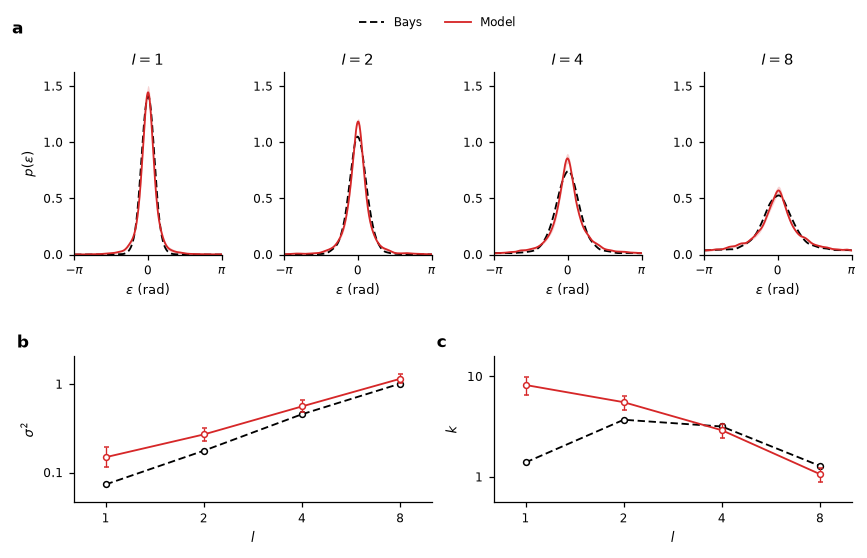

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_2/20261020/sparse_sharp_100_gp_10seeds/143436/fit_overlay_M100_10seeds.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_2/20261020/sparse_sharp_100_gp_10seeds/143436/fit_overlay_M100_10seeds.pdf
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_2/fig_2_fit_sparse_sharp.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_2/fig_2_fit_sparse_sharp.pdf
  For the caption: a linear axes; b log y-axis; c log y-axis; l on a log x-axis in b and c. Bands and error bars: 95% CI over 10 population seeds (variance: geometric mean).


In [54]:
# === Figure: fitted model against Bays, mean over seeds with 95% CI (Fig. 6) ===
MAIN_KURT_SPEC = plot_fit_figure(main_results,
                                 stem=f'fit_overlay_M{M}_{N_SEEDS}seeds',
                                 thesis_stem=thesis_name('fig_2_fit'))

## Fixed-CV Sweep

At each CV in `CV_VALUES` and each population seed, fits only (`width`, `gamma`)
with the CV held fixed. Within a seed, each CV's search also starts from the
previous CV's best point. Results are summarised across seeds as above. The
pilot analysis below tests whether differences between CVs exceed the
differences between population draws at the same CV (the confound raised in
Correction 3).

In [55]:
# === Fixed-CV Sweep - bind to the global control ===
CV_VALUES = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
SWEEP_N_TRIALS_METRIC = 10_000          # moment pool per set size, per CV and seed
SWEEP_TAG = f'M{M}_{DISTRIBUTION}_{MODEL}_{N_SEEDS}seeds'
PER_CV_FIGURES = (DISTRIBUTION == 'gamma')   # per-value detail figures: thesis sampler only

print('=== Fixed-CV Sweep ===')
print(f'  M = {M}, DISTRIBUTION = {DISTRIBUTION!r}, MODEL = {MODEL!r}')
print(f'  sweep parameter = {HET_TEXT}, values = {CV_VALUES}')
print(f'  per-value detail figures: {"yes" if PER_CV_FIGURES else "no (appendix uses the summary only)"}')
print(f'  seeds     = {N_SEEDS}  {SEED_BASES}')
print(f'  Bays ref  = {bays_meta["cache_filename"]}  (fixed M={M_BAYS_REF})')

=== Fixed-CV Sweep ===
  M = 100, DISTRIBUTION = 'sparse_sharp', MODEL = 'gp'
  sweep parameter = jitter, values = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
  per-value detail figures: no (appendix uses the summary only)
  seeds     = 10  [12345, 112345, 212345, 312345, 412345, 512345, 612345, 712345, 812345, 912345]
  Bays ref  = bays_cache_omega0.52_gamma119_M100_N10000_seed12345.npz  (fixed M=100)


In [ ]:
# === Fixed-CV sweep: one (width, gamma) fit per CV and per seed ===
X0_FIXED = [LAMBDA_TARGET, GAMMA_TARGET]
LO_FIXED, HI_FIXED = LO[:2], HI[:2]
SWEEP_GRID_LAMBDA      = np.geomspace(0.45, 1.6, 4)
SWEEP_GRID_WIDTH       = SWEEP_GRID_LAMBDA if MODEL == 'gp' else SWEEP_GRID_LAMBDA ** 2
SWEEP_GRID_GAMMA_TOTAL = np.geomspace(30.0, 480.0, 4)    # Hz, whole population
SWEEP_NM_MAXFEV        = 50

sweep_results = {cv: [] for cv in CV_VALUES}
t_all = time.time()
for s, pop_seed in enumerate(SEED_BASES):
    prev_best = None
    for cv in CV_VALUES:
        t0 = time.time()
        cands = [np.array([w, g / M]) for w in SWEEP_GRID_WIDTH for g in SWEEP_GRID_GAMMA_TOTAL]
        cands.append(np.asarray(X0_FIXED, dtype=float))
        if prev_best is not None:
            cands.append(prev_best)
        res = fit_grid_nm(make_cost(pop_seed, sigma_fixed=cv), cands, LO_FIXED, HI_FIXED,
                          nm_maxfev=SWEEP_NM_MAXFEV, nm_step=NM_STEP,
                          label=f'seed {s}, {HET_TEXT}={cv}', verbose=False)
        prev_best = res.x.copy()
        r = finish_fit(res, pop_seed, sigma_value=cv,
                       n_trials_metric=SWEEP_N_TRIALS_METRIC, sigma_fixed=cv)
        r['seed_index'], r['cv'] = s, cv
        sweep_results[cv].append(r)
        edge = '  (best grid point on the grid edge)' if r['at_grid_edge'] else ''
        print(f'  seed {s}, {HET_TEXT}={cv:<4g}: omega={r["omega"]:.3f}  '
              f'gamma_total={r["gamma_total"]:.1f} Hz  cost={r["cost"]:.4f}  '
              f'held-out={r["heldout_cost"]:.4f}  ({time.time() - t0:.0f}s){edge}')
print(f'Sweep done in {time.time() - t_all:.0f}s')

print('\n=== Sweep summary: mean [95% CI] across seeds ===')
print(f'{HET_TEXT:>12}  {"omega":>22}  {"gamma_total (Hz)":>24}  {"cost":>22}')
for cv in CV_VALUES:
    cells = []
    for key in ('omega', 'gamma_total', 'cost'):
        m, lo, hi = mean_ci([r[key] for r in sweep_results[cv]])
        cells.append(f'{m:8.3f} [{lo:6.3f},{hi:6.3f}]')
    print(f'{cv:>12g}  ' + '  '.join(cells))
if 'noise_floor' in globals():
    print(f'(noise floor from the Bays self-check: {noise_floor:.4f})')

append_fit_log([fit_log_row(r, 'cv_sweep', cv) for cv in CV_VALUES for r in sweep_results[cv]])

  seed 0, jitter=0.1 : omega=2.399  gamma_total=215.8 Hz  cost=0.3517  held-out=0.5056  (43s)  (best grid point on the grid edge)
  seed 0, jitter=0.5 : omega=3.448  gamma_total=190.5 Hz  cost=0.6088  held-out=0.7294  (38s)  (best grid point on the grid edge)
  seed 0, jitter=1   : omega=3.248  gamma_total=176.2 Hz  cost=0.7910  held-out=0.8616  (38s)  (best grid point on the grid edge)
  seed 0, jitter=2   : omega=2.560  gamma_total=498.3 Hz  cost=0.7540  held-out=0.9008  (33s)  (best grid point on the grid edge)
  seed 0, jitter=5   : omega=0.456  gamma_total=140.9 Hz  cost=0.8355  held-out=0.9478  (39s)
  seed 0, jitter=10  : omega=0.208  gamma_total=198.4 Hz  cost=0.5405  held-out=0.6562  (39s)  (best grid point on the grid edge)
  seed 1, jitter=0.1 : omega=2.122  gamma_total=211.2 Hz  cost=0.2900  held-out=0.3379  (41s)  (best grid point on the grid edge)
  seed 1, jitter=0.5 : omega=1.094  gamma_total=87.1 Hz  cost=0.8557  held-out=1.0158  (23s)
  seed 1, jitter=1   : omega=1.04

In [ ]:
# === Per-value figures (appendix): shared axes so values are directly comparable ===
sweep_summaries = {cv: summarise_seeds(sweep_results[cv]) for cv in CV_VALUES}
_bays_var  = np.array([data_moments[N]['variance'] for N in SET_SIZES])
_bays_kurt = np.array([data_moments[N]['kurtosis'] for N in SET_SIZES])
SWEEP_VAR_LIM = log_ylim(np.concatenate(
    [_bays_var] + [np.concatenate(sweep_summaries[cv]['var_ci'][1:]) for cv in CV_VALUES]))
SWEEP_KURT_SPEC = kurtosis_axis_spec(np.concatenate(
    [_bays_kurt] + [np.concatenate(sweep_summaries[cv]['kurt_ci'][1:]) for cv in CV_VALUES]))

if PER_CV_FIGURES:
    for cv in CV_VALUES:
        plot_fit_figure(sweep_results[cv],
                        stem=f'cv_sweep_{SWEEP_TAG}_{HET_KEY}{str(cv).replace(".", "p")}',
                        thesis_stem=f'exp2_cv_{cv:g}',
                        var_lim=SWEEP_VAR_LIM, kurt_spec=SWEEP_KURT_SPEC)
else:
    print(f'Per-value figures skipped for {DISTRIBUTION}; the appendix uses the main-fit '
          f'and summary figures. Set PER_CV_FIGURES = True to draw them.')

Per-value figures skipped for folded_normal; the appendix uses the main-fit and summary figures. Set PER_CV_FIGURES = True to draw them.


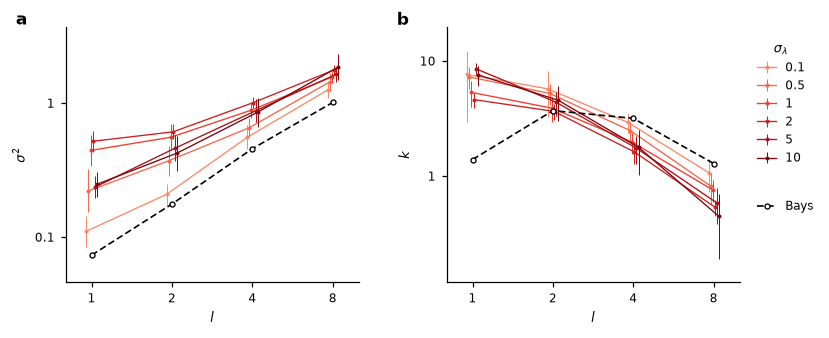

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_2/20261020/folded_normal_100_gp_10seeds/011654/cv_sweep_M100_folded_normal_gp_10seeds_variance_kurtosis.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_2/20261020/folded_normal_100_gp_10seeds/011654/cv_sweep_M100_folded_normal_gp_10seeds_variance_kurtosis.pdf
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_2/fig_2_sweep_folded_normal.png
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/thesis_figures/experiment_2/fig_2_sweep_folded_normal.pdf
  For the caption: a log y-axis; b log y-axis; l on a log x-axis. Error bars: 95% CI over 10 population seeds (variance: geometric mean); p

In [ ]:
# === Summary figure: variance and kurtosis against l, every sweep value (Fig. 7) ===
_cmap = mpl.colormaps['Reds']
sweep_colors = [to_hex(_cmap(v)) for v in np.linspace(0.40, 0.95, len(CV_VALUES))]
x_offsets = np.exp(np.linspace(-0.045, 0.045, len(CV_VALUES)))  # keep error bars apart
sizes = np.array(SET_SIZES, dtype=float)

with mpl.rc_context(NATURE_STYLE):
    fig, (ax_v, ax_k) = plt.subplots(1, 2, figsize=(7.2, 2.8))
    fig.subplots_adjust(left=0.08, right=0.86, bottom=0.17, top=0.93, wspace=0.30)
    for ax, key, bays in ((ax_v, 'var_ci', _bays_var), (ax_k, 'kurt_ci', _bays_kurt)):
        for i, cv in enumerate(CV_VALUES):
            m, lo, hi = sweep_summaries[cv][key]
            ax.errorbar(sizes * x_offsets[i], m, yerr=np.vstack([m - lo, hi - m]),
                        color=sweep_colors[i], lw=0.8, elinewidth=0.6, capsize=0,
                        marker='o', ms=2.4, mew=0, label=f'{cv:g}', zorder=3 + i)
        ax.plot(sizes, bays, color=BAYS_COLOR, lw=1.0, linestyle=BAYS_LINESTYLE,
                marker='o', ms=3.0, mfc='white', mew=0.8, label='Bays', zorder=20)
        setsize_axis(ax)
        _style_axes(ax)
    log_y_axis(ax_v, *SWEEP_VAR_LIM, r'$\sigma^2$')
    apply_kurtosis_axis(ax_k, SWEEP_KURT_SPEC)
    _panel_letter(ax_v, 'a', x=-0.17, y=1.06)
    _panel_letter(ax_k, 'b', x=-0.17, y=1.06)

    # Legends to the right: the sweep values under the parameter's name, Bays below.
    handles, labels = ax_v.get_legend_handles_labels()
    value_items = [(h, lab) for h, lab in zip(handles, labels) if lab != 'Bays']
    bays_items = [(h, lab) for h, lab in zip(handles, labels) if lab == 'Bays']
    leg_values = fig.legend(*zip(*value_items), loc='upper left', bbox_to_anchor=(0.875, 0.90),
                            frameon=False, title=HET_TEX, title_fontsize=8,
                            handlelength=1.6, labelspacing=0.45, borderaxespad=0.0)
    fig.legend(*zip(*bays_items), loc='upper left', bbox_to_anchor=(0.875, 0.43),
               frameon=False, handlelength=1.6, borderaxespad=0.0)

    saved = save_figure(fig, f'cv_sweep_{SWEEP_TAG}_variance_kurtosis',
                        thesis_name('fig_2_sweep'))
    plt.show()

print('Saved:\n  ' + '\n  '.join(str(path) for path in saved))
print(f'  For the caption: a log y-axis; b {SWEEP_KURT_SPEC[0]} y-axis; l on a log x-axis. '
      f'Error bars: 95% CI over {N_SEEDS} population seeds (variance: geometric mean); '
      f'points are offset slightly along l so the error bars do not overlap.')

## How many seeds? Pilot analysis and CV comparisons

Run with the 5-seed pilot first. This cell:

1. shows what a given number of seeds buys: the 95% CI half-width and the smallest
   paired difference detected with 80% power, both in units of the between-seed SD;
2. estimates, from the pilot's between-seed spread, how many seeds the reported
   main-fit numbers need for a CI within about ±10% (planned with the 80% upper
   confidence limit of the pilot SD, because an SD from five seeds is uncertain);
3. tests each CV against CV = 0.1, paired by seed, and computes the seeds each
   difference needs for 80% power (Holm-corrected p-values on the pilot);
4. compares variability **between** CVs with variability **between seeds at the
   same CV** (one-way ANOVA), which is the confound the examiner raised;
5. recommends `N_SEEDS` for the final run.

Differences that would need more than `N_MAX` seeds are reported as not reliably
different rather than chased with more runs.

In [ ]:
# === How many seeds? Pilot analysis, CV comparisons, recommendation ===
PRECISION_REL  = 0.10   # target 95% CI half-width: about +/-10% of the value
KURT_ABS_FLOOR = 0.25   # kurtosis target half-width: max(10% of |mean|, 0.25)
POWER, ALPHA   = 0.80, 0.05
N_MAX          = 50     # differences needing more seeds than this are reported as unresolved
PLAN_WITH_UCL  = True   # plan with the 80% upper confidence limit of the pilot SD

n_pilot = N_SEEDS
pilot_ok = n_pilot >= 3
if not pilot_ok:
    print('Run at least 3 seeds for the pilot analysis.')
else:
    def _plan_sd(sd):
        return sd_upper_limit(sd, n_pilot) if PLAN_WITH_UCL else sd

    # ---- 1. what a number of seeds buys --------------------------------------
    print('1) What a given number of seeds buys (units: between-seed SD)')
    print(f'   {"seeds":>5}  {"95% CI half-width":>18}  {"smallest difference at 80% power":>34}')
    for k in (5, 10, 20, 30):
        print(f'   {k:>5}  {ci_halfwidth_in_sd(k):>18.2f}  '
              f'{smallest_detectable_d(k, POWER, ALPHA):>34.2f}')

    # ---- 2. precision of the main-fit numbers ---------------------------------
    print('\n2) Seeds needed for precise main-fit estimates')
    s_main = summarise_seeds(main_results)
    main_cost = np.array([r['cost'] for r in main_results])
    items = [('fit cost', main_cost, PRECISION_REL * abs(main_cost.mean()))]
    items += [(f'log variance, l={N}', np.log(s_main['var'][:, j]), np.log(1 + PRECISION_REL))
              for j, N in enumerate(SET_SIZES)]
    items += [(f'kurtosis, l={N}', s_main['kurt'][:, j],
               max(PRECISION_REL * abs(s_main['kurt'][:, j].mean()), KURT_ABS_FLOOR))
              for j, N in enumerate(SET_SIZES)]
    precision_rows = []
    for label, vals, target in items:
        sd = float(np.std(vals, ddof=1))
        need = seeds_for_precision(_plan_sd(sd), target)
        precision_rows.append((label, sd, target, need))
        print(f'   {label:<20} between-seed SD {sd:8.4f}   target +/-{target:.3f}   -> {need} seeds')

    # ---- 3. CV differences, paired by seed ------------------------------------
    def _quantity(results, kind, j=None):
        if kind == 'cost':
            return np.array([r['cost'] for r in results])
        s = summarise_seeds(results)
        return np.log(s['var'][:, j]) if kind == 'logvar' else s['kurt'][:, j]

    quantities = ([('fit cost', 'cost', None)]
                  + [(f'log variance, l={N}', 'logvar', j) for j, N in enumerate(SET_SIZES)]
                  + [(f'kurtosis, l={N}', 'kurt', j) for j, N in enumerate(SET_SIZES)])
    cv_ref = CV_VALUES[0]
    comp_rows = []
    for cv in CV_VALUES[1:]:
        for label, kind, j in quantities:
            diff = _quantity(sweep_results[cv], kind, j) - _quantity(sweep_results[cv_ref], kind, j)
            sd = float(np.std(diff, ddof=1))
            d = np.inf if sd == 0 else float(diff.mean()) / _plan_sd(sd)
            need = seeds_for_power(d, POWER, ALPHA)
            p = float(stats.ttest_1samp(diff, 0.0).pvalue) if sd > 0 else np.nan
            comp_rows.append([cv, label, float(diff.mean()), sd, d, need, p])
    p_adj = holm([row[6] for row in comp_rows])
    print(f'\n3) Each {HET_TEXT} value against {HET_TEXT} = {cv_ref:g}, paired by seed '
          f'(d uses the {"upper-limit " if PLAN_WITH_UCL else ""}pilot SD)')
    print(f'   {HET_TEXT:>12}  {"quantity":<20} {"mean diff":>10} {"SD":>8} {"d":>7} '
          f'{"seeds for 80%":>13} {"p (Holm)":>9}')
    for row, pa in zip(comp_rows, p_adj):
        cv, label, mdiff, sd, d, need, _ = row
        print(f'   {cv:>12g}  {label:<20} {mdiff:>10.4f} {sd:>8.4f} {d:>7.2f} '
              f'{str(need):>13} {pa:>9.3g}')

    # ---- 4. between-CV vs between-seed variability ----------------------------
    print(f'\n4) Between-{HET_TEXT} vs between-seed variability (one-way ANOVA across {HET_TEXT} values)')
    for label, kind, j in quantities:
        groups = [_quantity(sweep_results[cv], kind, j) for cv in CV_VALUES]
        F, p = stats.f_oneway(*groups)
        between = float(np.std([g.mean() for g in groups], ddof=1))
        within = float(np.sqrt(np.mean([np.var(g, ddof=1) for g in groups])))
        ratio = between / within if within > 0 else np.inf
        print(f'   {label:<20} F = {F:9.2f}   p = {p:.2g}   '
              f'between-value SD / within-value SD = {ratio:.2f}')
    print('   (The ANOVA ignores the pairing by seed, so it is conservative.)')

    # ---- 5. recommendation -----------------------------------------------------
    needs = ([(row[3], f'precision of {row[0]}') for row in precision_rows]
             + [(row[5], f'{HET_TEXT}={row[0]:g} vs {cv_ref:g}, {row[1]}') for row in comp_rows])
    feasible = [(n, why) for n, why in needs if np.isfinite(n) and n <= N_MAX]
    unresolved = [why for n, why in needs if not (np.isfinite(n) and n <= N_MAX)]
    n_needed, driver = max(feasible, default=(n_pilot, 'pilot size'))
    N_RECOMMENDED = int(max(n_pilot, n_needed))
    print(f'\n5) Recommended number of population seeds: {N_RECOMMENDED}')
    print(f'   largest requirement: {driver} ({n_needed} seeds)')
    if unresolved:
        print(f'   Needing more than {N_MAX} seeds (report as not reliably different, '
              f'or loosen the precision target):')
        for why in unresolved:
            print(f'     - {why}')
    print(f'   Set N_SEEDS = {N_RECOMMENDED} in the Experiment Control cell and rerun '
          f'for the final figures.')

1) What a given number of seeds buys (units: between-seed SD)
   seeds   95% CI half-width    smallest difference at 80% power
       5                1.24                                1.68
      10                0.72                                1.00
      20                0.47                                0.66
      30                0.37                                0.53

2) Seeds needed for precise main-fit estimates
   fit cost             between-seed SD   0.0393   target +/-0.018   -> 35 seeds
   log variance, l=1    between-seed SD   0.3172   target +/-0.095   -> 74 seeds
   log variance, l=2    between-seed SD   0.2386   target +/-0.095   -> 43 seeds
   log variance, l=4    between-seed SD   0.1712   target +/-0.095   -> 24 seeds
   log variance, l=8    between-seed SD   0.1845   target +/-0.095   -> 27 seeds
   kurtosis, l=1        between-seed SD   3.2964   target +/-1.006   -> 72 seeds
   kurtosis, l=2        between-seed SD   1.8189   target +/-0.740   -> 42 seed

In [ ]:
# === Save results: per-seed parameters, across-seed summaries, raw results ===
import pickle

params_path = OUTPUT_DIR / 'exp2_parameters_by_seed.csv'
with open(params_path, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['fit', 'cv_fixed', 'seed_index', 'pop_seed', 'width', 'omega',
                'gamma_total_hz', HET_KEY, 'cost', 'heldout_cost', 'nfev', 'nm_moved_log'])
    for kind, results in [('main', main_results)] + [('cv_sweep', sweep_results[cv])
                                                      for cv in CV_VALUES]:
        for r in results:
            w.writerow([kind, r.get('cv', ''), r['seed_index'], r['seed_base'], r['width'],
                        r['omega'], r['gamma_total'], r['sigma'], r['cost'],
                        r['heldout_cost'], r['nfev'], r['nm_moved_log']])

summary_path = OUTPUT_DIR / 'exp2_moments_summary.csv'
with open(summary_path, 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['fit', 'set_size', 'n_seeds', 'bays_variance', 'model_variance_geomean',
                'variance_ci_lo', 'variance_ci_hi', 'bays_kurtosis', 'model_kurtosis_mean',
                'kurtosis_ci_lo', 'kurtosis_ci_hi'])
    for label, results in [('main', main_results)] + [(f'{HET_KEY}={cv:g}', sweep_results[cv])
                                                       for cv in CV_VALUES]:
        s = summarise_seeds(results)
        (gm, glo, ghi), (km, klo, khi) = s['var_ci'], s['kurt_ci']
        for j, N in enumerate(SET_SIZES):
            w.writerow([label, N, len(results), data_moments[N]['variance'], gm[j], glo[j],
                        ghi[j], data_moments[N]['kurtosis'], km[j], klo[j], khi[j]])

raw_path = OUTPUT_DIR / 'exp2_seed_results.pkl'
with open(raw_path, 'wb') as f:
    pickle.dump({'config': {'M': M, 'MODEL': MODEL, 'DISTRIBUTION': DISTRIBUTION,
                            'N_SEEDS': N_SEEDS, 'SEED_BASES': SEED_BASES,
                            'SET_SIZES': SET_SIZES, 'CV_VALUES': CV_VALUES,
                            'FIT_OBJECTIVE': FIT_OBJECTIVE, 'N_TRIALS_FIT': N_TRIALS_FIT,
                            'noise_floor': globals().get('noise_floor', np.nan)},
                 'main_results': main_results, 'sweep_results': sweep_results}, f)

print('Saved:')
for p in (params_path, summary_path, raw_path):
    print(f'  {p}')

Saved:
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_2/20261020/folded_normal_100_gp_10seeds/011654/exp2_parameters_by_seed.csv
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_2/20261020/folded_normal_100_gp_10seeds/011654/exp2_moments_summary.csv
  /Users/yashbharti/Desktop/Research/mphil/mixed_selectivity_pfc_v0.1/mixed_selective_model/simulated_experiments/bays_2014/result_data/experiment_2/20261020/folded_normal_100_gp_10seeds/011654/exp2_seed_results.pkl
